In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Informalidad por departamento

`dane-data` define la informalidad por **seguridad social**: un ocupado es formal si está afiliado a salud y
cotiza a pensión (vea {doc}`../guia/variables`). La tasa oficial del DANE usa además el tamaño de la
empresa, así que los niveles no son iguales a los publicados.

In [2]:
import dane_data as dd

dpto = dd.geih.serie_indicadores(2025, por="departamento")
dpto[["departamento", "ocupados", "tasa_informalidad", "n_muestra"]].sort_values("tasa_informalidad").round(1)

,departamento,ocupados,tasa_informalidad,n_muestra
26,San Andrés,20982.9,28.1,8340
4,Bogotá D.C.,4322854.5,36.0,26316
13,Cundinamarca,1740859.3,43.9,16190
1,Antioquia,3383382.5,46.8,47177
31,Vaupés,5321.8,48.7,5235
25,Risaralda,463756.1,49.8,36638
7,Caldas,481833.3,51.2,38633
23,Putumayo,17166.2,51.7,4347
30,Valle del Cauca,2122393.6,52.1,41246
9,Casanare,81569.7,53.1,5223


Cada departamento tiene una muestra distinta; las cifras de los departamentos con pocas observaciones
(`n_muestra`) tienen más error de muestreo.

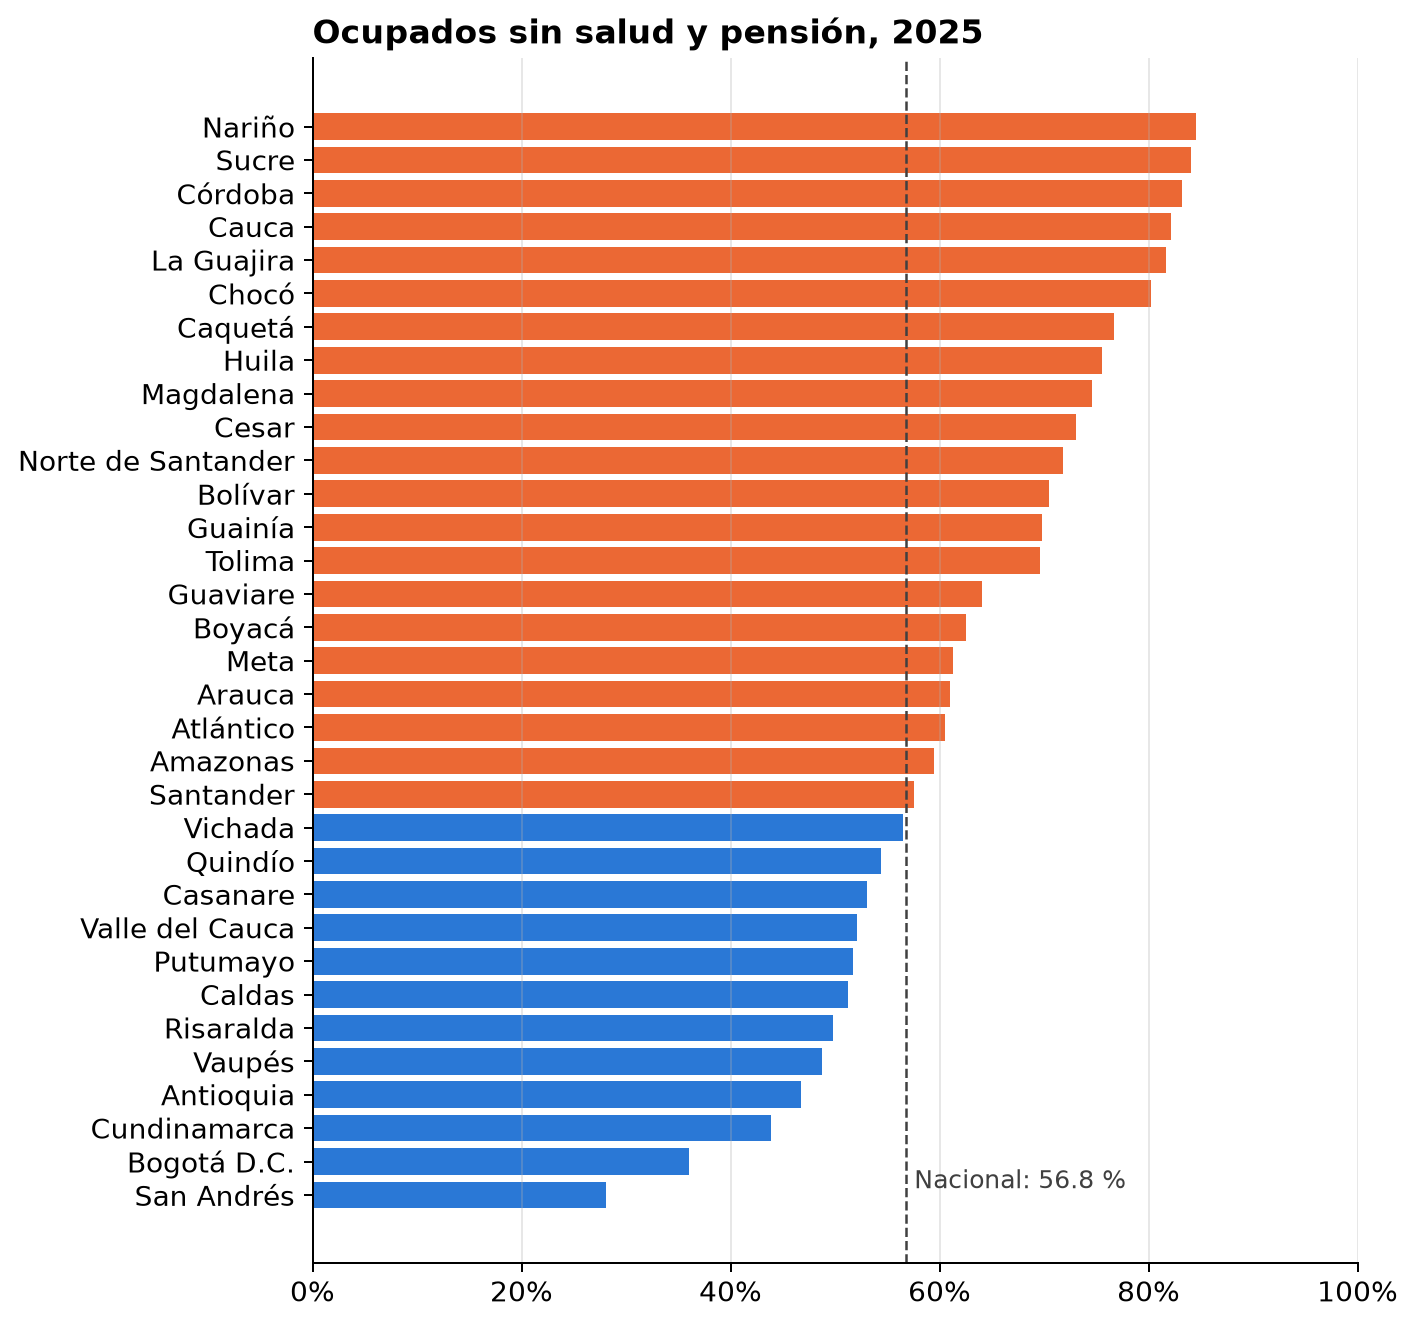

In [3]:
d = dpto.dropna(subset=["departamento"]).sort_values("tasa_informalidad")
nacional = dd.geih.serie_indicadores(2025)["tasa_informalidad"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 7.5))
colores = ["#eb6834" if t > nacional else "#2a78d6" for t in d["tasa_informalidad"]]
ax.barh(d["departamento"].astype(str), d["tasa_informalidad"], color=colores)
ax.axvline(nacional, color="0.25", lw=1, ls="--")
ax.text(nacional + 0.8, 0.2, f"Nacional: {nacional:.1f} %", fontsize=10, color="0.25")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 100)
ax.set_title("Ocupados sin salud y pensión, 2025")
ax.grid(axis="y", visible=False)
fig.tight_layout();

## Por zona y nivel educativo

In [4]:
zona = dd.geih.serie_indicadores(2025, por="zona")[["zona", "tasa_informalidad"]]
educ = dd.geih.serie_indicadores(2025, por="nivel_educativo")[["nivel_educativo", "tasa_informalidad"]]
zona.round(1), educ.dropna().round(1)

(                                  zona  tasa_informalidad
 0                    Urbano (cabecera)               49.8
 1  Rural (centros poblados y disperso)               83.9,
   nivel_educativo  tasa_informalidad
 0         Ninguno               96.2
 1        Primaria               86.3
 2      Secundaria               82.0
 3           Media               59.3
 4        Superior               26.4)

La informalidad es mucho mayor en la zona rural y baja con la educación: entre quienes tienen educación
superior es una fracción de la de quienes solo tienen primaria.

## En el tiempo

In [5]:
serie = dd.geih.serie_indicadores(range(2022, 2026), por="zona")
serie.pivot(index="anio", columns="zona", values="tasa_informalidad").round(1)

zona,Urbano (cabecera),Rural (centros poblados y disperso)
anio,,
2022,51.9,85.3
2023,50.5,84.6
2024,49.9,84.5
2025,49.8,83.9
